# Práctica 6. Puerta de Hadamard

## Información general

**Asignatura:** Computación cuántica  
**Sesión:** 6  
**Título:** Puerta de Hadamard
**Modalidad:** Individual  
**Entorno recomendado:** Jupyter Notebook  
**Bibliotecas:** NumPy, Matplotlib, Qiskit y Qiskit Aer

## Objetivos

En esta práctica vas a estudiar la puerta de Hadamard desde tres puntos de vista:

- Cálculo manual con vectores y matrices.
- Implementación con NumPy.
- Construcción y simulación de circuitos con Qiskit.

Al finalizar la práctica deberás ser capaz de:

- Escribir la matriz de Hadamard.
- Aplicar Hadamard sobre $|0\rangle$ y $|1\rangle$.
- Interpretar los estados $|+\rangle$ y $|-\rangle$.
- Comprobar que $H^2 = I$.
- Entender Hadamard como cambio entre la base $Z$ y la base $X$.
- Construir superposiciones uniformes con varios qubits.
- Analizar cómo una fase relativa puede convertirse en una diferencia de probabilidad.
- Comparar probabilidades teóricas y conteos experimentales.

## Entrega

Entrega este notebook completado con código ejecutado, resultados visibles, tablas completadas, respuestas razonadas y conclusión final.

## 1. Preparación del entorno

Ejecuta la siguiente celda para importar las bibliotecas necesarias.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

def applyStyle():
    plt.style.use("default")

    plt.rcParams["font.family"] = "serif"
    plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif", "serif"]
    plt.rcParams["font.size"] = 12
    plt.rcParams["axes.labelsize"] = 12
    plt.rcParams["axes.titlesize"] = 12
    plt.rcParams["xtick.labelsize"] = 10
    plt.rcParams["ytick.labelsize"] = 10
    plt.rcParams["legend.fontsize"] = 10

    plt.rcParams["xtick.direction"] = "in"
    plt.rcParams["ytick.direction"] = "in"
    plt.rcParams["xtick.top"] = True
    plt.rcParams["ytick.right"] = True
    plt.rcParams["xtick.minor.visible"] = True
    plt.rcParams["ytick.minor.visible"] = True

    plt.rcParams["lines.linewidth"] = 1.0
    plt.rcParams["lines.markersize"] = 3

    plt.rcParams["legend.frameon"] = True
    plt.rcParams["legend.edgecolor"] = "black"
    plt.rcParams["legend.fancybox"] = False

COLOR_TARGET = "#5d54a4"
COLOR_PRED = "#9154a4"
COLOR_ERR = "#404040"

SEED = 42
np.set_printoptions(precision=5, suppress=True)

applyStyle()


def probsDict(state, decimals=5):
    return {str(k): round(float(v), decimals) for k, v in state.probabilities_dict().items()}

## 2. Parte A. Hadamard con matrices

### Ejercicio 1. Definición de estados y matriz de Hadamard

Define con NumPy los estados:

$$
|0\rangle =
\begin{pmatrix}
1 \\
0
\end{pmatrix}
$$

$$
|1\rangle =
\begin{pmatrix}
0 \\
1
\end{pmatrix}
$$

y la matriz:

$$
H =
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1 & 1 \\
1 & -1
\end{pmatrix}
$$

Muestra $|0\rangle$, $|1\rangle$, $H$ y la forma de cada array con `.shape`.

In [2]:
ket0 = np.array([1, 0], dtype=complex)
ket1 = np.array([0, 1], dtype=complex)

H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)

for name, array in [("|0>", ket0), ("|1>", ket1), ("H", H)]:
    print(f"{name} =")
    print(array)
    print(f"  shape = {array.shape}")
    print()

print(f"H unitary (H†H = I)?  {np.allclose(H.conj().T @ H, np.eye(2))}")
print(f"H hermitian (H† = H)? {np.allclose(H.conj().T, H)}")

|0> =
[1.+0.j 0.+0.j]
  shape = (2,)

|1> =
[0.+0.j 1.+0.j]
  shape = (2,)

H =
[[ 0.70711+0.j  0.70711+0.j]
 [ 0.70711+0.j -0.70711+0.j]]
  shape = (2, 2)

H unitary (H†H = I)?  True
H hermitian (H† = H)? True


**Responde:**

1. ¿Qué dimensión tienen los estados $|0\rangle$ y $|1\rangle$?
2. ¿Qué dimensión tiene la matriz $H$?
3. ¿Por qué tiene sentido multiplicar $H$ por un estado de un qubit?

**Respuesta:**

1. Dimensión 2. Son vectores de dos amplitudes, la de |0⟩ y la de |1⟩, y salen con `shape = (2,)`.

2. Es una matriz 2 × 2 (`shape = (2, 2)`).

3. Porque una puerta de un qubit tiene que llevar un vector de ℂ² a otro de ℂ², y eso es justo una matriz 2 × 2. El producto (2 × 2)·(2,) da otra vez un vector de 2 amplitudes. Además H es unitaria (`H unitary (H†H = I)?  True`), así que el resultado sigue teniendo norma 1 y es un estado válido.

### Ejercicio 2. Cálculo de $H|0\rangle$

Calcula con NumPy:

$$
H|0\rangle
$$

Después, desarrolla manualmente el producto en una celda Markdown.

In [3]:
stateH0 = H @ ket0

print(f"H|0> = {stateH0}")
print(f"norm = {np.linalg.norm(stateH0):.5f}")

H|0> = [0.70711+0.j 0.70711+0.j]
norm = 1.00000


Desarrollo manual:

$$
H|0\rangle =
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1 & 1 \\
1 & -1
\end{pmatrix}
\begin{pmatrix}
1 \\
0
\end{pmatrix}
=
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1\cdot 1 + 1\cdot 0 \\
1\cdot 1 + (-1)\cdot 0
\end{pmatrix}
=
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1 \\
1
\end{pmatrix}
=
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

Multiplicar por |0⟩ = (1, 0) es quedarse con la primera columna de H.

**Responde:**

1. ¿Qué estado se obtiene?
2. ¿Cuáles son sus amplitudes?
3. ¿Cuáles son sus probabilidades de medida?
4. ¿Qué nombre recibe este estado?

**Respuesta:**

1. (|0⟩ + |1⟩)/√2, que coincide con NumPy: `H|0> = [0.70711+0.j 0.70711+0.j]`.

2. α = 1/√2 ≈ 0.70711 y β = 1/√2 ≈ 0.70711, las dos reales y positivas.

3. P(0) = |1/√2|² = 1/2 y P(1) = |1/√2|² = 1/2.

4. |+⟩. Es una superposición equilibrada, con el mismo peso en |0⟩ y |1⟩ y sin fase relativa.

### Ejercicio 3. Cálculo de $H|1\rangle$

Calcula con NumPy:

$$
H|1\rangle
$$

Después, desarrolla manualmente el producto en una celda Markdown.

In [4]:
stateH1 = H @ ket1

print(f"H|1> = {stateH1}")
print(f"norm = {np.linalg.norm(stateH1):.5f}")
print()
print(f"H|0> equals H|1>?                      {np.allclose(stateH0, stateH1)}")
print(f"they only differ in the sign of |1>?   {np.allclose(stateH0 * np.array([1, -1]), stateH1)}")

H|1> = [ 0.70711+0.j -0.70711+0.j]
norm = 1.00000

H|0> equals H|1>?                      False
they only differ in the sign of |1>?   True


Desarrollo manual:

$$
H|1\rangle =
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1 & 1 \\
1 & -1
\end{pmatrix}
\begin{pmatrix}
0 \\
1
\end{pmatrix}
=
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1\cdot 0 + 1\cdot 1 \\
1\cdot 0 + (-1)\cdot 1
\end{pmatrix}
=
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1 \\
-1
\end{pmatrix}
=
\frac{|0\rangle - |1\rangle}{\sqrt{2}}
$$

Ahora sale la segunda columna de H.

**Responde:**

1. ¿Qué estado se obtiene?
2. ¿Cuáles son sus amplitudes?
3. ¿Cuáles son sus probabilidades de medida?
4. ¿Qué diferencia hay entre este estado y $H|0\rangle$?

**Respuesta:**

1. (|0⟩ − |1⟩)/√2, es decir |−⟩. NumPy da `H|1> = [ 0.70711+0.j -0.70711+0.j]`.

2. α = 1/√2 y β = −1/√2.

3. P(0) = 1/2 y P(1) = |−1/√2|² = 1/2, igual que H|0⟩. El signo desaparece al hacer el módulo al cuadrado.

4. Solo el signo de la amplitud de |1⟩, + en H|0⟩ y − en H|1⟩ (`they only differ in the sign of |1>?   True`). Como afecta a una sola componente es una fase relativa, no global, así que son estados distintos aunque den las mismas probabilidades. De hecho son ortogonales (ejercicio 10).

### Ejercicio 4. Función para calcular probabilidades

Implementa una función que devuelva las probabilidades de medir 0 y 1 en la base computacional.

In [5]:
def computeProbabilities(state, tolerance=1e-10):
    state = np.asarray(state, dtype=complex)

    if state.shape != (2,):  # does it have exactly two amplitudes?
        raise ValueError("The state must have exactly two amplitudes")

    if not np.all(np.isfinite(state)):  # are all amplitudes finite?
        raise ValueError("The state contains non-finite values")

    if not np.isclose(np.linalg.norm(state), 1.0, atol=tolerance):  # is it normalized?
        raise ValueError("The state is not normalized")

    probs = np.abs(state) ** 2  # Born rule: |amplitude|²

    return {0: float(probs[0]), 1: float(probs[1])}

In [6]:
states = {
    "|0>": ket0,
    "|1>": ket1,
    "H|0>": stateH0,
    "H|1>": stateH1,
}

print(f"{'state':>5} | {'P(0)':>5} {'P(1)':>5} | {'sum':>4}")
print("-" * 27)
for name, state in states.items():
    p = computeProbabilities(state)
    print(f"{name:>5} | {p[0]:>5.2f} {p[1]:>5.2f} | {p[0] + p[1]:>4.2f}")

print()

invalidCases = {
    "notNormalized": ([1, 1], "norm sqrt(2) != 1"),
    "wrongDimension": ([1, 0, 0], "3 amplitudes"),
    "withNan": ([np.nan, 1], "NaN amplitude"),
}

for name, (vector, justification) in invalidCases.items():
    try:
        computeProbabilities(vector)
        outcome = "NOT DETECTED"
    except ValueError:
        outcome = "ValueError"
    print(f"{name:15s} -> {outcome:12s} | {justification}")

state |  P(0)  P(1) |  sum
---------------------------
  |0> |  1.00  0.00 | 1.00
  |1> |  0.00  1.00 | 1.00
 H|0> |  0.50  0.50 | 1.00
 H|1> |  0.50  0.50 | 1.00

notNormalized   -> ValueError   | norm sqrt(2) != 1
wrongDimension  -> ValueError   | 3 amplitudes
withNan         -> ValueError   | NaN amplitude


Completa la tabla:

| Estado | P(0) | P(1) |
|---|---:|---:|
| $\|0\rangle$ | 1 | 0 |
| $\|1\rangle$ | 0 | 1 |
| $H\|0\rangle$ | 0.5 | 0.5 |
| $H\|1\rangle$ | 0.5 | 0.5 |

He añadido a la función las comprobaciones de las prácticas anteriores (dos amplitudes, valores finitos y norma 1), así que con un vector que no es un estado válido lanza `ValueError` en vez de devolver unas "probabilidades" que no suman 1.

## 3. Parte B. Propiedad $H^2=I$

### Ejercicio 5. Comprobación matricial

Calcula con NumPy:

$$
H^2
$$

y compara el resultado con la matriz identidad.

In [7]:
H2 = H @ H
I = np.eye(2, dtype=complex)

print("H^2 =")
print(H2)
print()
print("I =")
print(I)
print()

print(f"H^2 = I (np.allclose)? {np.allclose(H2, I)}")
print(f"H^2 = I (exact ==)?    {np.array_equal(H2, I)}")
print(f"max |H^2 - I|          = {np.max(np.abs(H2 - I)):.2e}")
print(f"H^2[0, 0]              = {H2[0, 0].real!r}")

H^2 =
[[ 1.+0.j -0.+0.j]
 [-0.+0.j  1.+0.j]]

I =
[[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]

H^2 = I (np.allclose)? True
H^2 = I (exact ==)?    False
max |H^2 - I|          = 2.22e-16
H^2[0, 0]              = np.float64(0.9999999999999998)


**Responde:**

1. ¿Qué matriz se obtiene al calcular $H^2$?
2. ¿Qué significa que $H^2=I$?
3. ¿Por qué puede haber pequeñas diferencias numéricas?
4. ¿Por qué usamos `np.allclose` en lugar de `==`?

**Respuesta:**

1. La identidad. A mano: H² = ½·((1, 1), (1, −1))·((1, 1), (1, −1)) = ½·((2, 0), (0, 2)) = I. En la salida aparecen `-0.` fuera de la diagonal, que son ceros con signo de la coma flotante.

2. Que H es su propia inversa. Aplicarla dos veces deja cualquier estado como estaba, así que lo que hace una H lo deshace la siguiente.

3. Porque 1/√2 no se puede guardar exacto en coma flotante. Al multiplicar se acumula el error de redondeo y sale `H^2[0, 0] = 0.9999999999999998` en vez de 1, con una diferencia máxima de `2.22e-16`.

4. Por eso mismo. Con `==` sale `H^2 = I (exact ==)? False` aunque matemáticamente son iguales, y `np.allclose` compara con un margen y da `True`.

### Ejercicio 6. Aplicar Hadamard dos veces a un estado

Calcula:

$$
HH|0\rangle
$$

y:

$$
HH|1\rangle
$$

In [8]:
stateHH0 = H @ H @ ket0
stateHH1 = H @ H @ ket1

for name, state, original in [("HH|0>", stateHH0, ket0), ("HH|1>", stateHH1, ket1)]:
    print(f"{name} = {state}   equal to the initial state? {np.allclose(state, original)}")

HH|0> = [ 1.+0.j -0.+0.j]   equal to the initial state? True
HH|1> = [-0.+0.j  1.+0.j]   equal to the initial state? True


**Responde:**

1. ¿Qué ocurre al aplicar Hadamard dos veces sobre $|0\rangle$?
2. ¿Qué ocurre al aplicarla dos veces sobre $|1\rangle$?
3. ¿Cómo se relaciona esto con $H^2=I$?

**Respuesta:**

1. Vuelve a |0⟩. La primera H lo lleva a |+⟩ y la segunda lo devuelve (`equal to the initial state? True`).

2. Vuelve a |1⟩, pasando por |−⟩. El `-0.` de la salida es otra vez un cero con signo.

3. Es la misma propiedad aplicada a un estado concreto: HH|ψ⟩ = H²|ψ⟩ = I|ψ⟩ = |ψ⟩. Como vale para |0⟩ y |1⟩, que forman una base, vale para cualquier estado.

## 4. Parte C. Hadamard con Qiskit

### Ejercicio 7. Circuito con una puerta Hadamard

Crea un circuito de un qubit y aplica Hadamard.

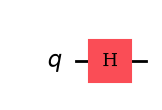

<IPython.core.display.Latex object>

vector        = [0.70711+0.j 0.70711+0.j]
probabilities = {'0': 0.5, '1': 0.5}
equal to H @ ket0 (NumPy)? True


In [9]:
qcH = QuantumCircuit(1)
qcH.h(0)

stateQiskitH = Statevector.from_instruction(qcH)

display(qcH.draw("mpl"))
display(stateQiskitH.draw("latex"))

print(f"vector        = {stateQiskitH.data}")
print(f"probabilities = {probsDict(stateQiskitH)}")
print(f"equal to H @ ket0 (NumPy)? {np.allclose(stateQiskitH.data, stateH0)}")

**Responde:**

1. ¿Cuál es el estado inicial por defecto en Qiskit?
2. ¿Qué estado se obtiene después de aplicar $H$?
3. ¿Coincide con el cálculo de NumPy?

**Respuesta:**

1. |0⟩. Qiskit inicializa todos los qubits en |0⟩.

2. |+⟩ = (√2/2)|0⟩ + (√2/2)|1⟩, como lo dibuja `draw("latex")` (√2/2 = 1/√2), con `probabilities = {'0': 0.5, '1': 0.5}`.

3. Sí, sale `equal to H @ ket0 (NumPy)? True`.

### Ejercicio 8. Circuito con dos puertas Hadamard

Crea un circuito de un qubit con dos puertas Hadamard consecutivas.

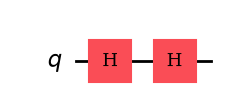

<IPython.core.display.Latex object>

vector        = [1.+0.j 0.+0.j]
probabilities = {'0': 1.0}
depth         = 2
equal to |0>?           True
equal to HH|0> (NumPy)? True


In [10]:
qcHH = QuantumCircuit(1)
qcHH.h(0)
qcHH.h(0)

stateQiskitHH = Statevector.from_instruction(qcHH)

display(qcHH.draw("mpl"))
display(stateQiskitHH.draw("latex"))

print(f"vector        = {stateQiskitHH.data}")
print(f"probabilities = {probsDict(stateQiskitHH)}")
print(f"depth         = {qcHH.depth()}")
print(f"equal to |0>?           {np.allclose(stateQiskitHH.data, ket0)}")
print(f"equal to HH|0> (NumPy)? {np.allclose(stateQiskitHH.data, stateHH0)}")

**Responde:**

1. ¿Qué estado final se obtiene?
2. ¿Por qué?
3. ¿Qué propiedad de Hadamard se comprueba?

**Respuesta:**

1. |0⟩, con `probabilities = {'0': 1.0}`.

2. Porque la primera H pasa |0⟩ a |+⟩ y la segunda deshace la superposición. Las dos contribuciones a |1⟩ son +½ y −½, se cancelan, y las de |0⟩ se suman. El circuito tiene dos puertas (`depth = 2`) pero hace lo mismo que uno vacío.

3. H² = I, igual que en el ejercicio 6 con NumPy (`equal to HH|0> (NumPy)? True`).

### Ejercicio 9. Comparación $H|0\rangle$, $HH|0\rangle$, $HZH|0\rangle$

Construye tres circuitos:

- Circuito A: $H|0\rangle$
- Circuito B: $HH|0\rangle$
- Circuito C: $HZH|0\rangle$

Para cada circuito muestra el circuito, el estado final y las probabilidades.

Circuit A


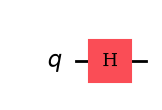

<IPython.core.display.Latex object>

probabilities = {'0': 0.5, '1': 0.5}
  vector          = [0.70711+0.j 0.70711+0.j]
  equal to NumPy? True

Circuit B


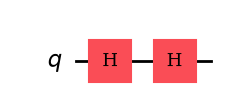

<IPython.core.display.Latex object>

probabilities = {'0': 1.0}
  vector          = [1.+0.j 0.+0.j]
  equal to NumPy? True

Circuit C


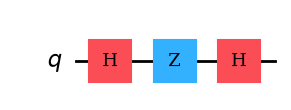

<IPython.core.display.Latex object>

probabilities = {'1': 1.0}
  vector          = [0.+0.j 1.+0.j]
  equal to NumPy? True

HZH = X? True


In [11]:
def analyzeCircuit(qc):
    state = Statevector.from_instruction(qc)

    display(qc.draw("mpl"))
    display(state.draw("latex"))

    probs = probsDict(state)
    print(f"probabilities = {probs}")

    return state, probs


X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

qcA = QuantumCircuit(1)
qcA.h(0)

qcB = QuantumCircuit(1)
qcB.h(0)
qcB.h(0)

qcC = QuantumCircuit(1)
qcC.h(0)
qcC.z(0)  # only changes the sign of |1>
qcC.h(0)

# with matrices the order is reversed: H, then Z, then H is H @ Z @ H
numpyStates = {"A": H @ ket0, "B": H @ H @ ket0, "C": H @ Z @ H @ ket0}
circuits = {"A": qcA, "B": qcB, "C": qcC}
results = {}

for name, qc in circuits.items():
    print(f"Circuit {name}")
    state, probs = analyzeCircuit(qc)
    results[name] = (state, probs)
    print(f"  vector          = {state.data}")
    print(f"  equal to NumPy? {np.allclose(state.data, numpyStates[name])}")
    print()

stateA, probsA = results["A"]
stateB, probsB = results["B"]
stateC, probsC = results["C"]

print(f"HZH = X? {np.allclose(H @ Z @ H, X)}")

Completa la tabla:

| Circuito | Operaciones | Estado final | P(0) | P(1) |
|---|---|---|---:|---:|
| A | $H\|0\rangle$ | \|+⟩ = (\|0⟩ + \|1⟩)/√2 | 0.5 | 0.5 |
| B | $HH\|0\rangle$ | \|0⟩ | 1 | 0 |
| C | $HZH\|0\rangle$ | \|1⟩ | 0 | 1 |

**Responde:**

1. ¿Qué diferencia hay entre los circuitos B y C?
2. ¿Por qué una puerta $Z$, que solo cambia una fase, modifica el resultado final?
3. ¿Qué relación tiene este ejemplo con la interferencia?

**Respuesta:**

1. C tiene una Z entre las dos H, y eso cambia el resultado de siempre 0 a siempre 1. Los dos son deterministas, pero con el resultado contrario.

2. Porque la Z actúa cuando el qubit está en |+⟩, y ahí no es una fase global sino relativa: Z|+⟩ = |−⟩. Justo después de la Z las probabilidades siguen en 0.5 y 0.5, pero la segunda H convierte |−⟩ en |1⟩. De hecho HZH = X (`HZH = X? True`), así que el circuito C equivale a una puerta NOT.

3. Es interferencia. La última H suma las amplitudes de |0⟩ y |1⟩ para dar la de |0⟩ y las resta para dar la de |1⟩. En B, con el signo +, se suman en |0⟩ y se cancelan en |1⟩ (constructiva en 0, destructiva en 1). En C el signo − de la Z le da la vuelta y se cancelan en |0⟩. La fase decide qué resultado sobrevive.

## 5. Parte D. Base Z y base X

### Ejercicio 10. Construcción de $|+\rangle$ y $|-\rangle$

Define con NumPy:

$$
|+\rangle =
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

$$
|-\rangle =
\frac{|0\rangle - |1\rangle}{\sqrt{2}}
$$

Comprueba que $H|0\rangle = |+\rangle$ y que $H|1\rangle = |-\rangle$.

In [12]:
ketPlus = (ket0 + ket1) / np.sqrt(2)
ketMinus = (ket0 - ket1) / np.sqrt(2)

print(f"|+> = {ketPlus}")
print(f"|-> = {ketMinus}")
print()

print(f"H|0> = |+>? {np.allclose(H @ ket0, ketPlus)}")
print(f"H|1> = |->? {np.allclose(H @ ket1, ketMinus)}")
print()

print(f"<+|+> = {np.vdot(ketPlus, ketPlus):.5f}")
print(f"<-|-> = {np.vdot(ketMinus, ketMinus):.5f}")
print(f"<+|-> = {np.vdot(ketPlus, ketMinus):.5f}")

|+> = [0.70711+0.j 0.70711+0.j]
|-> = [ 0.70711+0.j -0.70711+0.j]

H|0> = |+>? True
H|1> = |->? True

<+|+> = 1.00000+0.00000j
<-|-> = 1.00000+0.00000j
<+|-> = -0.00000+0.00000j


**Responde:**

1. ¿Por qué $|+\rangle$ y $|-\rangle$ forman otra base?
2. ¿Qué nombre recibe esta base?
3. ¿Qué diferencia hay entre medir en la base Z y medir en la base X?

**Respuesta:**

1. Porque están normalizados (`<+|+> = 1`, `<-|-> = 1`) y son ortogonales (`<+|-> = 0`). Dos vectores ortonormales en ℂ² ya forman una base, así que cualquier estado de un qubit se puede escribir como combinación de |+⟩ y |−⟩.

2. La base X (o base de Hadamard), porque |+⟩ y |−⟩ son los autoestados de X, con autovalores +1 y −1.

3. En la base Z los resultados son |0⟩ o |1⟩, y la medida solo ve |⟨0|ψ⟩|² y |⟨1|ψ⟩|². En la base X los resultados son |+⟩ o |−⟩, con probabilidades |⟨+|ψ⟩|² y |⟨−|ψ⟩|². Un mismo estado da resultados distintos según la base: |+⟩ es aleatorio en Z (50/50) pero determinista en X (siempre +). Con |0⟩ pasa al revés.

### Ejercicio 11. Hadamard como cambio de base

Comprueba con NumPy:

$$
H|+\rangle = |0\rangle
$$

$$
H|-\rangle = |1\rangle
$$

In [13]:
stateHPlus = H @ ketPlus
stateHMinus = H @ ketMinus

print(f"H|+> = {stateHPlus}")
print(f"H|-> = {stateHMinus}")
print()

print(f"H|+> = |0>? {np.allclose(stateHPlus, ket0)}")
print(f"H|-> = |1>? {np.allclose(stateHMinus, ket1)}")
print()

# the columns of H are |+> and |->
print(f"column 0 of H = |+>? {np.allclose(H[:, 0], ketPlus)}")
print(f"column 1 of H = |->? {np.allclose(H[:, 1], ketMinus)}")

H|+> = [1.+0.j 0.+0.j]
H|-> = [0.+0.j 1.+0.j]

H|+> = |0>? True
H|-> = |1>? True

column 0 of H = |+>? True
column 1 of H = |->? True


**Responde:**

1. ¿Qué ocurre al aplicar Hadamard a $|+\rangle$?
2. ¿Qué ocurre al aplicar Hadamard a $|-\rangle$?
3. ¿Por qué decimos que Hadamard cambia entre la base Z y la base X?

**Respuesta:**

1. Se convierte en |0⟩ (`H|+> = |0>? True`).

2. Se convierte en |1⟩ (`H|-> = |1>? True`).

3. Porque H lleva |0⟩ ↔ |+⟩ y |1⟩ ↔ |−⟩ en los dos sentidos. Sus columnas son justo |+⟩ y |−⟩ (`column 0 of H = |+>? True`), así que H es la matriz de cambio de base, y como H² = I sirve para ir y para volver. En la práctica, para medir en la base X se aplica H y luego se mide en la Z: un 0 significa |+⟩ y un 1 significa |−⟩.

## 6. Parte E. Hadamard y medida

### Ejercicio 12. Medida del estado $|+\rangle$

Construye un circuito que prepare $|+\rangle$ y lo mida con `shots = 1000`.

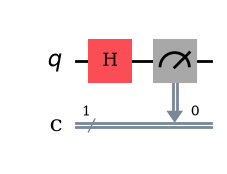

counts       = {'1': 486, '0': 514}
total        = 1000
frequencies  = {'1': 0.486, '0': 0.514}
|f(0) - 0.5| = 0.0140   (sigma_f = 0.0158)


In [14]:
shots = 1000

qcMeasurePlus = QuantumCircuit(1, 1)
qcMeasurePlus.h(0)  # |+>
qcMeasurePlus.measure(0, 0)

display(qcMeasurePlus.draw("mpl"))

simulator = AerSimulator(seed_simulator=SEED)
qcTranspiled = transpile(qcMeasurePlus, simulator)
result = simulator.run(qcTranspiled, shots=shots).result()
countsPlus = result.get_counts()

freqsPlus = {k: v / shots for k, v in countsPlus.items()}
sigma = np.sqrt(0.5 * 0.5 / shots)

print(f"counts       = {countsPlus}")
print(f"total        = {sum(countsPlus.values())}")
print(f"frequencies  = {freqsPlus}")
print(f"|f(0) - 0.5| = {abs(freqsPlus.get('0', 0) - 0.5):.4f}   (sigma_f = {sigma:.4f})")

**Responde:**

1. ¿Qué resultados se esperan aproximadamente?
2. ¿Deben aparecer exactamente 500 ceros y 500 unos?
3. ¿Qué representa el número de shots?
4. ¿La medida devuelve el estado completo?

**Respuesta:**

1. Alrededor de 500 ceros y 500 unos, porque |+⟩ tiene P(0) = P(1) = 0.5.

2. No. Salen 514 y 486. Cada shot es aleatorio, y la desviación típica de la frecuencia es σ_f = √(0.5·0.5/1000) ≈ 0.016. Aquí |f(0) − 0.5| = 0.014, menos de 1σ, así que es una fluctuación normal.

3. Cuántas veces se repite el experimento completo: preparar |+⟩, medir y guardar el bit. Cada shot parte de cero, porque la medida colapsa el estado.

4. No. Cada shot da solo un 0 o un 1, y con muchos shots solo se estiman |α|² y |β|². La fase se pierde, y |−⟩ daría un resultado parecido.

### Ejercicio 13. Efecto del número de shots

Repite la medida del estado $|+\rangle$ para distintos números de shots.

In [15]:
shotsList = [10, 100, 1_000, 10_000]
shotsResults = []

for n in shotsList:
    simulator = AerSimulator(seed_simulator=SEED)
    qcTranspiled = transpile(qcMeasurePlus, simulator)
    result = simulator.run(qcTranspiled, shots=n).result()
    counts = result.get_counts()

    n0 = counts.get("0", 0)
    n1 = counts.get("1", 0)

    shotsResults.append({
        "shots": n,
        "N0": n0,
        "N1": n1,
        "f0": n0 / n,
        "f1": n1 / n,
        "E0": abs(n0 / n - 0.5),
        "sigma": 0.5 / np.sqrt(n),
    })

print(f"{'shots':>6} | {'N(0)':>5} {'N(1)':>5} | {'f(0)':>6} {'f(1)':>6} | {'|f(0)-1/2|':>10} | {'0.5/sqrt(N)':>11}")
print("-" * 68)
for r in shotsResults:
    print(f"{r['shots']:>6} | {r['N0']:>5} {r['N1']:>5} | {r['f0']:>6.4f} {r['f1']:>6.4f} | {r['E0']:>10.4f} | {r['sigma']:>11.4f}")

 shots |  N(0)  N(1) |   f(0)   f(1) | |f(0)-1/2| | 0.5/sqrt(N)
--------------------------------------------------------------------
    10 |     5     5 | 0.5000 0.5000 |     0.0000 |      0.1581
   100 |    49    51 | 0.4900 0.5100 |     0.0100 |      0.0500
  1000 |   514   486 | 0.5140 0.4860 |     0.0140 |      0.0158
 10000 |  4921  5079 | 0.4921 0.5079 |     0.0079 |      0.0050


Completa la tabla:

| Shots | N(0) | N(1) | f(0) | f(1) |
|---:|---:|---:|---:|---:|
| 10 | 5 | 5 | 0.5000 | 0.5000 |
| 100 | 49 | 51 | 0.4900 | 0.5100 |
| 1.000 | 514 | 486 | 0.5140 | 0.4860 |
| 10.000 | 4921 | 5079 | 0.4921 | 0.5079 |

**Responde:**

1. ¿Qué ocurre con las frecuencias al aumentar el número de shots?
2. ¿Coinciden siempre exactamente con las probabilidades teóricas?
3. ¿Qué relación hay con la ley de los grandes números?

**Respuesta:**

1. Tienden a 0.5, pero no de forma monótona. El error |f(0) − 0.5| sale 0, 0.01, 0.014 y 0.0079, y sube de 100 a 1.000 shots. Lo que sí baja siempre es el error esperado, 0.5/√N (0.158, 0.05, 0.016 y 0.005).

2. No. Con 10 shots coincide exactamente (5 y 5), pero es casualidad. En las demás filas hay una diferencia pequeña. Con 10.000 shots el error, 0.0079, es unas 1.6σ, algo grande pero normal.

3. La ley de los grandes números dice que la frecuencia converge a la probabilidad cuando N → ∞, y la tabla lo muestra. Pero no dice que cada fila sea mejor que la anterior. La incertidumbre baja como 1/√N, así que para reducirla 10 veces hacen falta 100 veces más shots.

Como cada fila crea el simulador con la misma semilla, las filas no son independientes: los primeros 10 resultados de la fila de 100 son los mismos que los de la fila de 10. Por eso la fila de 1.000 coincide exactamente con el ejercicio 12 (514 y 486).

### Ejercicio 14. Histograma de resultados

Representa en un diagrama de barras los conteos obtenidos para `shots=1000`.

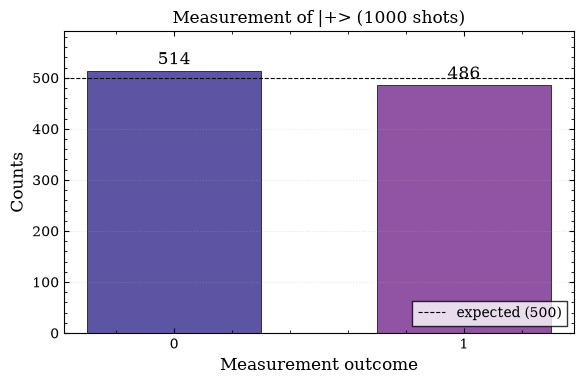

In [16]:
labels = sorted(countsPlus)
values = [countsPlus[k] for k in labels]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, values, color=[COLOR_TARGET, COLOR_PRED], width=0.6, edgecolor="black", linewidth=0.5)
ax.axhline(shots / 2, color="black", linestyle="--", linewidth=0.8, label=f"expected ({shots // 2})")

for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 5, str(value), ha="center", va="bottom")

ax.set_xlabel("Measurement outcome")
ax.set_ylabel("Counts")
ax.set_title(f"Measurement of |+> ({shots} shots)")
ax.set_ylim(0, max(values) * 1.15)
ax.legend(loc="lower right")
ax.grid(True, axis="y", linestyle=":", alpha=0.3)

plt.tight_layout()
plt.show()

**Responde:**

1. ¿Qué muestra el histograma?
2. ¿Muestra la fase relativa?
3. ¿Por qué un histograma no describe completamente el estado cuántico?

**Respuesta:**

1. Cuántas veces salió cada resultado en los 1000 shots: 514 veces 0 y 486 veces 1. La línea discontinua marca los 500 esperados.

2. No. Solo muestra conteos, que estiman |α|² y |β|². |+⟩ y |−⟩ darían el mismo histograma, porque solo cambia el signo de β.

3. Porque el estado son amplitudes complejas, con módulo y fase, y el histograma solo recoge (aproximadamente) los módulos al cuadrado en una base. Para ver la fase hay que cambiar de base antes de medir, por ejemplo con una H (ejercicio 9), o medir en varias bases (tomografía).

## 7. Parte F. Hadamard en varios qubits

### Ejercicio 15. Hadamard en dos qubits

Crea un circuito de dos qubits y aplica Hadamard a ambos.

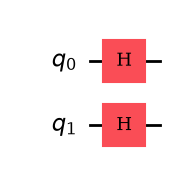

<IPython.core.display.Latex object>

vector        = [0.5+0.j 0.5+0.j 0.5+0.j 0.5+0.j]
probabilities = {'00': 0.25, '01': 0.25, '10': 0.25, '11': 0.25}
equal to |+> ⊗ |+> (NumPy)? True


In [17]:
qc2 = QuantumCircuit(2)
qc2.h(0)
qc2.h(1)

state2 = Statevector.from_instruction(qc2)

display(qc2.draw("mpl"))
display(state2.draw("latex"))

print(f"vector        = {state2.data}")
print(f"probabilities = {probsDict(state2)}")
print(f"equal to |+> ⊗ |+> (NumPy)? {np.allclose(state2.data, np.kron(ketPlus, ketPlus))}")

**Responde:**

1. ¿Cuántos estados aparecen en la superposición?
2. ¿Cuáles son?
3. ¿Qué probabilidad tiene cada uno?
4. ¿Por qué las probabilidades son iguales?

**Respuesta:**

1. Cuatro.

2. |00⟩, |01⟩, |10⟩ y |11⟩, todos los posibles con dos qubits.

3. 1/4 cada uno. Las amplitudes son todas 1/2 y |1/2|² = 0.25 (`{'00': 0.25, '01': 0.25, '10': 0.25, '11': 0.25}`).

4. Porque cada H deja su qubit en |+⟩, 50/50, y los dos qubits son independientes. El estado es el producto |+⟩ ⊗ |+⟩ (`equal to |+> ⊗ |+> (NumPy)? True`), así que cada combinación tiene probabilidad ½ · ½ = ¼. Todas las amplitudes además tienen signo +.

### Ejercicio 16. Hadamard en tres qubits

Crea un circuito de tres qubits y aplica Hadamard a todos ellos.

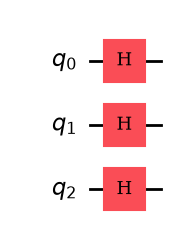

<IPython.core.display.Latex object>

{'000': 0.125, '001': 0.125, '010': 0.125, '011': 0.125, '100': 0.125, '101': 0.125, '110': 0.125, '111': 0.125}
States with non-zero probability: 8
all equal to 1/8?                 True
equal to |+>⊗|+>⊗|+> (NumPy)?     True


In [18]:
qc3 = QuantumCircuit(3)
for qubit in range(3):
    qc3.h(qubit)

state3 = Statevector.from_instruction(qc3)
probs3 = probsDict(state3)

display(qc3.draw("mpl"))
display(state3.draw("latex"))

print(probs3)
print(f"States with non-zero probability: {len(probs3)}")
print(f"all equal to 1/8?                 {all(np.isclose(p, 1 / 8) for p in probs3.values())}")
print(f"equal to |+>⊗|+>⊗|+> (NumPy)?     {np.allclose(state3.data, np.kron(np.kron(ketPlus, ketPlus), ketPlus))}")

**Responde:**

1. ¿Cuántos estados aparecen?
2. ¿Qué probabilidad tiene cada uno?
3. ¿Cómo se relaciona este resultado con $2^n$?
4. ¿Qué ocurriría con 4 qubits?

**Respuesta:**

1. Ocho, de |000⟩ a |111⟩ (`States with non-zero probability: 8`).

2. 1/8 = 0.125 cada uno, con amplitud √2/4 = 1/√8.

3. Con n qubits hay 2ⁿ cadenas de bits, y H en todos los qubits las pone todas con el mismo peso. Para n = 3 son 2³ = 8 estados con probabilidad 1/2³.

4. Saldrían 2⁴ = 16 estados con probabilidad 1/16 = 0.0625 cada uno. Lo compruebo en el reto (ejercicio 20).

### Ejercicio 17. Medida de una superposición uniforme de tres qubits

Crea un circuito de tres qubits y tres bits clásicos. Aplica Hadamard a los tres qubits, mide todos y ejecuta con `shots = 1000`.

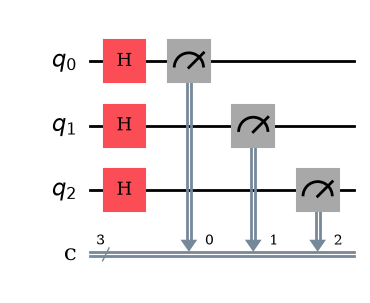

outcome |    N |      f | |f - 1/8| | in 2 sigma
-------------------------------------------------
    000 |  107 |  0.107 |    0.0180 |       True
    001 |  137 |  0.137 |    0.0120 |       True
    010 |  136 |  0.136 |    0.0110 |       True
    011 |  121 |  0.121 |    0.0040 |       True
    100 |  123 |  0.123 |    0.0020 |       True
    101 |  127 |  0.127 |    0.0020 |       True
    110 |  115 |  0.115 |    0.0100 |       True
    111 |  134 |  0.134 |    0.0090 |       True

total = 1000, expected per outcome = 125, sigma_f = 0.0105


In [19]:
shots = 1000

qc3Measure = QuantumCircuit(3, 3)
for qubit in range(3):
    qc3Measure.h(qubit)
qc3Measure.measure(range(3), range(3))  # qi -> ci

display(qc3Measure.draw("mpl"))

simulator = AerSimulator(seed_simulator=SEED)
qcTranspiled = transpile(qc3Measure, simulator)
result = simulator.run(qcTranspiled, shots=shots).result()
counts3 = result.get_counts()

expected = shots / 8
sigma3 = np.sqrt((1 / 8) * (7 / 8) / shots)
outcomes3 = [format(k, "03b") for k in range(8)]

print(f"{'outcome':>7} | {'N':>4} | {'f':>6} | {'|f - 1/8|':>9} | {'in 2 sigma':>10}")
print("-" * 49)
for outcome in outcomes3:
    n = counts3.get(outcome, 0)
    f = n / shots
    print(f"{outcome:>7} | {n:>4} | {f:>6.3f} | {abs(f - 1 / 8):>9.4f} | {str(abs(f - 1 / 8) < 2 * sigma3):>10}")
print()
print(f"total = {sum(counts3.values())}, expected per outcome = {expected:.0f}, sigma_f = {sigma3:.4f}")

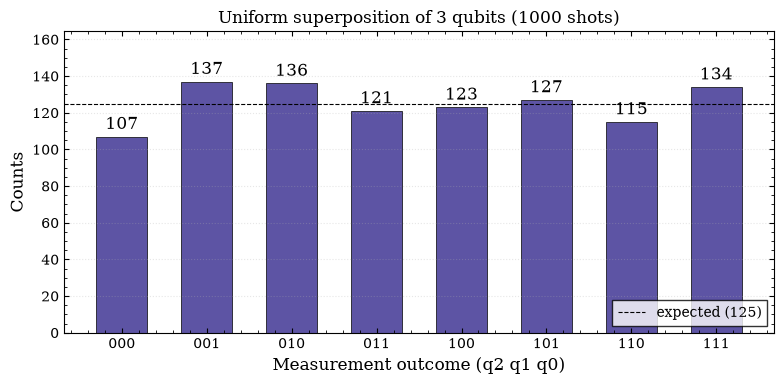

In [20]:
labels = outcomes3
values = [counts3.get(k, 0) for k in labels]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, values, color=COLOR_TARGET, width=0.6, edgecolor="black", linewidth=0.5)
ax.axhline(expected, color="black", linestyle="--", linewidth=0.8, label=f"expected ({expected:.0f})")

for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 2, str(value), ha="center", va="bottom")

ax.set_xlabel("Measurement outcome (q2 q1 q0)")
ax.set_ylabel("Counts")
ax.set_title(f"Uniform superposition of 3 qubits ({shots} shots)")
ax.set_ylim(0, max(values) * 1.2)
ax.legend(loc="lower right")
ax.grid(True, axis="y", linestyle=":", alpha=0.3)

plt.tight_layout()
plt.show()

**Responde:**

1. ¿Aparecen todos los estados posibles?
2. ¿Aparecen todos con exactamente el mismo número de conteos?
3. ¿Qué se espera teóricamente?
4. ¿Por qué hay diferencias entre los conteos observados?

**Respuesta:**

1. Sí, salen los 8, de `000` a `111`.

2. No. Van de 107 (`000`) a 137 (`001`).

3. 1000/8 = 125 de cada uno, porque todos tienen probabilidad 1/8.

4. Porque cada shot es aleatorio y con 1000 shots hay error estadístico. Para cada resultado σ_f = √((1/8)(7/8)/1000) ≈ 0.0105, unos 10 conteos. Todas las diferencias están dentro de 2σ (la columna `in 2 sigma` sale `True` en las 8 filas), así que el resultado es compatible con una distribución uniforme.

## 8. Parte G. Superposición frente a mezcla clásica

### Ejercicio 18. Comparación conceptual

Considera dos situaciones:

Situación A:

- Se prepara el estado $|+\rangle$.
- Se mide en la base computacional.

Situación B:

- El 50 % de las veces se prepara $|0\rangle$.
- El 50 % de las veces se prepara $|1\rangle$.
- Se mide en la base computacional.

**Responde:**

1. ¿Producen ambas situaciones las mismas probabilidades al medir en la base computacional?
2. ¿Son físicamente equivalentes?
3. ¿Qué información conserva la superposición que no conserva la mezcla clásica?
4. ¿Qué operación permitiría distinguirlas?

**Respuesta:**

1. Sí. Las dos dan P(0) = P(1) = 0.5 en la base Z, y sus histogramas no se pueden distinguir.

2. No. En A todos los shots preparan el mismo estado puro, |+⟩. En B cada shot el sistema ya está en |0⟩ o en |1⟩, y lo único que no sabemos es en cuál. Son situaciones distintas aunque coincidan en esta medida.

3. La coherencia, es decir, la fase relativa bien definida entre |0⟩ y |1⟩. En |+⟩ las dos amplitudes existen a la vez con signo + y pueden interferir. En la mezcla no hay amplitudes que sumar, solo probabilidades clásicas.

4. Aplicar una H antes de medir, que equivale a medir en la base X. Lo desarrollo en el ejercicio 19.

### Ejercicio 19. Verificación con Hadamard

Explica qué ocurre si antes de medir aplicamos una puerta Hadamard a:

- El estado $|+\rangle$.
- Una mezcla clásica formada por $|0\rangle$ y $|1\rangle$ al 50 %.

**Responde:**

1. ¿Qué ocurre con $|+\rangle$ al aplicar $H$?
2. ¿Qué resultados se obtendrían en la mezcla clásica?
3. ¿Por qué esto demuestra que superposición no equivale a desconocimiento clásico?

**Respuesta:**

1. H|+⟩ = |0⟩, así que sale 0 siempre. En la simulación de la celda siguiente salen `{'0': 1000}`.

2. 50/50 otra vez. La mitad de las veces el estado es |0⟩ y H lo lleva a |+⟩, que da 0 o 1 al 50 %. La otra mitad es |1⟩ y H lo lleva a |−⟩, que también da 50/50. En total, P(0) = ½·½ + ½·½ = ½. En la simulación sale `{'0': 520, '1': 480}`. Las dos mitades dan exactamente los mismos conteos (260/240) porque uso la misma semilla y |+⟩ y |−⟩ tienen las mismas probabilidades.

3. Porque si |+⟩ fuera "un 0 o un 1 que no conocemos", después de la H se comportaría como la mezcla y daría 50/50. Pero da 0 siempre. Eso solo se explica porque las amplitudes de |0⟩ y |1⟩ interfieren: se suman en |0⟩ y se cancelan en |1⟩. En la mezcla cada shot es un único estado y no hay nada con lo que interferir.

In [21]:
# |+> vs classical 50 % mixture of |0> and |1>, both with H before measuring
shots = 1000
simulator = AerSimulator(seed_simulator=SEED)

def runCounts(qc, n):
    return simulator.run(transpile(qc, simulator), shots=n).result().get_counts()

qcPlusH = QuantumCircuit(1, 1)
qcPlusH.h(0)  # |+>
qcPlusH.h(0)  # H before measuring
qcPlusH.measure(0, 0)

qcZeroH = QuantumCircuit(1, 1)  # half of the mixture: |0>
qcZeroH.h(0)
qcZeroH.measure(0, 0)

qcOneH = QuantumCircuit(1, 1)  # other half: |1>
qcOneH.x(0)
qcOneH.h(0)
qcOneH.measure(0, 0)

countsPlusH = runCounts(qcPlusH, shots)
countsZeroH = runCounts(qcZeroH, shots // 2)
countsOneH = runCounts(qcOneH, shots // 2)
countsMixtureH = {k: countsZeroH.get(k, 0) + countsOneH.get(k, 0) for k in ["0", "1"]}

print(f"|+> + H     -> {countsPlusH}")
print(f"mixture + H -> {countsMixtureH}   (|0> half: {countsZeroH}, |1> half: {countsOneH})")

|+> + H     -> {'0': 1000}
mixture + H -> {'0': 520, '1': 480}   (|0> half: {'0': 260, '1': 240}, |1> half: {'0': 260, '1': 240})


## 9. Reto avanzado

### Ejercicio 20. Generalización a $n$ qubits

Implementa una función que cree un circuito de `n` qubits con Hadamard aplicada a todos los qubits.

In [22]:
def hadamardCircuit(n):
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):  # bool is a subclass of int
        raise TypeError("n must be an integer")

    if n <= 0:
        raise ValueError("n must be positive")

    qc = QuantumCircuit(n)
    for qubit in range(n):
        qc.h(qubit)

    return qc

In [23]:
print(f"{'n':>2} | {'states':>6} | {'2^n':>4} | {'P each':>7} | {'1/2^n':>7} | uniform")
print("-" * 49)
for n in [1, 2, 3, 4]:
    qc = hadamardCircuit(n)
    state = Statevector.from_instruction(qc)
    probs = probsDict(state)
    pEach = list(probs.values())[0]
    uniform = all(np.isclose(p, 1 / 2**n) for p in probs.values())
    print(f"{n:>2} | {len(probs):>6} | {2**n:>4} | {pEach:>7.4f} | {1 / 2**n:>7.4f} | {uniform}")

print()

invalidCases = {
    "zero": (0, "n = 0"),
    "negative": (-2, "n < 0"),
    "float": (2.5, "not an integer"),
    "bool": (True, "bool is not a number of qubits"),
}

for name, (n, justification) in invalidCases.items():
    try:
        hadamardCircuit(n)
        outcome = "NOT DETECTED"
    except (TypeError, ValueError) as error:
        outcome = type(error).__name__
    print(f"{name:10s} -> {outcome:12s} | {justification}")

 n | states |  2^n |  P each |   1/2^n | uniform
-------------------------------------------------
 1 |      2 |    2 |  0.5000 |  0.5000 | True
 2 |      4 |    4 |  0.2500 |  0.2500 | True
 3 |      8 |    8 |  0.1250 |  0.1250 | True
 4 |     16 |   16 |  0.0625 |  0.0625 | True

zero       -> ValueError   | n = 0
negative   -> ValueError   | n < 0
float      -> TypeError    | not an integer
bool       -> TypeError    | bool is not a number of qubits


**Responde:**

1. ¿Cuántos estados aparecen para cada valor de `n`?
2. ¿Qué probabilidad tiene cada estado?
3. ¿Qué expresión general describe el estado creado?
4. ¿Por qué esto no significa que podamos leer todos los estados a la vez?

**Respuesta:**

1. 2ⁿ: 2, 4, 8 y 16 para n = 1, 2, 3 y 4, como sale en la columna `states`.

2. 1/2ⁿ cada uno: 0.5, 0.25, 0.125 y 0.0625. La columna `uniform` sale `True` en todas las filas.

3.

$$
H^{\otimes n}|0\rangle^{\otimes n} = |+\rangle^{\otimes n} = \frac{1}{\sqrt{2^n}}\sum_{x=0}^{2^n-1}|x\rangle
$$

Es una superposición uniforme de todas las cadenas de n bits, todas con amplitud 1/√2ⁿ y el mismo signo.

4. Porque al medir el estado colapsa y solo se obtiene una cadena de n bits, elegida al azar. Para "ver" las 2ⁿ habría que repetir muchísimas veces, y aun así solo tendríamos probabilidades, no las amplitudes. Los algoritmos cuánticos no leen todos los estados: usan interferencia (como en el ejercicio 9) para que las amplitudes de las respuestas incorrectas se cancelen y la buena quede con probabilidad alta antes de medir.

La función también valida `n` igual que `shots` en las prácticas anteriores: `TypeError` si no es un entero (incluido `bool`) y `ValueError` si no es positivo.

## 10. Pruebas mínimas

Incluye al final del notebook las siguientes pruebas. Deben ejecutarse sin errores cuando la práctica esté completada correctamente.

In [24]:
def raises(errorType, func, *args, **kwargs):
    try:
        func(*args, **kwargs)
        return False

    except errorType:
        return True

# Provided tests
assert np.allclose(H @ ket0, ketPlus)
assert np.allclose(H @ ket1, ketMinus)

I = np.eye(2, dtype=complex)
assert np.allclose(H @ H, I)

assert np.allclose(H @ ketPlus, ket0)
assert np.allclose(H @ ketMinus, ket1)

probsPlus = computeProbabilities(ketPlus)
assert np.isclose(probsPlus[0], 0.5)
assert np.isclose(probsPlus[1], 0.5)

qc = hadamardCircuit(3)
state = Statevector.from_instruction(qc)
probs = state.probabilities_dict()
assert len(probs) == 8

for p in probs.values():
    assert np.isclose(p, 1 / 8)

# Extra tests
assert np.allclose(H.conj().T @ H, I)                                   # H is unitary
assert np.allclose(stateQiskitH.data, stateH0)                          # Qiskit == NumPy
assert np.allclose(stateQiskitHH.data, ket0)                            # HH|0> = |0>
assert probsC == {"1": 1.0}                                             # HZH|0> = |1>
assert np.allclose(H @ Z @ H, X)                                        # HZH = X
assert np.isclose(np.vdot(ketPlus, ketMinus), 0)                        # |+> and |-> orthogonal
assert sum(countsPlus.values()) == 1000
assert all(r["N0"] + r["N1"] == r["shots"] for r in shotsResults)
assert sum(counts3.values()) == 1000
assert len(counts3) == 8                                                # all 8 outcomes appear
assert countsPlusH == {"0": 1000}                                       # H|+> = |0> always
assert len(Statevector.from_instruction(hadamardCircuit(4)).probabilities_dict()) == 16

# Invalid inputs
assert raises(ValueError, computeProbabilities, [1, 1])        # not normalized
assert raises(ValueError, computeProbabilities, [1, 0, 0])     # wrong dimension
assert raises(ValueError, computeProbabilities, [np.nan, 1])   # NaN
assert raises(ValueError, hadamardCircuit, 0)
assert raises(ValueError, hadamardCircuit, -2)
assert raises(TypeError, hadamardCircuit, 2.5)
assert raises(TypeError, hadamardCircuit, True)

print("All tests passed")

All tests passed


## 11. Conclusión final

Redacta una conclusión de entre 150 y 250 palabras respondiendo:

1. ¿Qué papel tiene la puerta de Hadamard en la computación cuántica?
2. ¿Por qué $|+\rangle$ y $|-\rangle$ no son el mismo estado aunque tengan las mismas probabilidades en la base computacional?
3. ¿Qué significa que $H^2=I$?
4. ¿Por qué Hadamard puede entenderse como un cambio de base?
5. ¿Qué diferencia hay entre superposición y mezcla clásica?
6. ¿Qué ocurre al aplicar Hadamard a varios qubits?

**Conclusión:**

La puerta de Hadamard es la forma básica de crear superposición: lleva |0⟩ a |+⟩ y |1⟩ a |−⟩, con 50/50 en la base computacional. Por eso aparece al principio de casi todos los algoritmos cuánticos, y también al final, para hacer interferir las amplitudes antes de medir.

|+⟩ y |−⟩ dan el mismo histograma, pero se diferencian en el signo de la amplitud de |1⟩. Es una fase relativa, no global, así que son estados distintos y de hecho ortogonales. La diferencia aparece en cuanto se aplica otra H: |+⟩ da siempre 0 y |−⟩ siempre 1.

Que H² = I significa que H es su propia inversa, de modo que dos H seguidas se anulan. Numéricamente no sale la identidad exacta (0.9999999999999998), por eso comparamos con `np.allclose`.

H es un cambio de base porque sus columnas son |+⟩ y |−⟩ e intercambia la base Z con la X en los dos sentidos. Medir en la base X equivale a aplicar H y medir en la Z.

Una superposición tiene una fase relativa definida y puede interferir. Una mezcla clásica es solo desconocimiento. Coinciden en la base Z, pero con una H delante |+⟩ da siempre 0 y la mezcla sigue en 50/50.

Con H en n qubits se obtiene una superposición uniforme de los 2ⁿ estados, cada uno con probabilidad 1/2ⁿ, aunque al medir solo se lee uno.